In [1]:
from typing import TypedDict, Dict
from langgraph.graph import StateGraph, START, END

In [14]:
class StateAgent(TypedDict):
    number1 :  int
    number2: int
    operator: str
    finalnumber : int

def adder(state: StateAgent)-> StateAgent:
    """This function will add two number"""
    state["finalnumber"] = state["number1"] + state["number2"]
    return state

def subtractor(state: StateAgent) -> StateAgent:
    """This function will sub two number"""
    state["finalnumber"] = state["number1"] - state["number2"]
    return state

def process_next_node(state: StateAgent) -> str:
    """This function will compare operator"""
    if state["operator"] == "+":
        return "add_operation"
    if state["operator"] == "-":
        return "sub_operation"
    

In [15]:
graph = StateGraph(StateAgent)

graph.add_node("add_node", adder)
graph.add_node("subtractor_node", subtractor)
graph.add_node("router", lambda state:state )
graph.add_edge(START, "router")
graph.add_conditional_edges(
    "router",
    process_next_node,
    {
        "add_operation":"add_node",
        "sub_operation": "subtractor_node"
    }
)
graph.add_edge("add_node", END)
graph.add_edge("subtractor_node", END)

app = graph.compile()

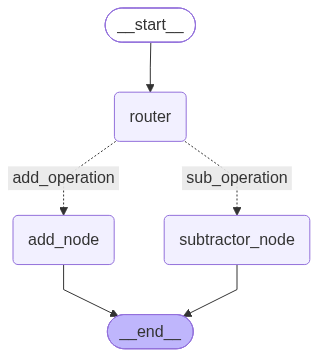

In [16]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [17]:
app.invoke({"number1": 7,"number2": 2, "operator":"-"})

{'number1': 7, 'number2': 2, 'operator': '-', 'finalnumber': 5}